# Classification Models

In [ ]:
import pandas as pd
df = pd.read_csv('https://raw.githubusercontent.com/ganjar87/data_science_practice/main/healthcare-dataset-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.tail()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [ ]:
#untuk melihat descriptive statistics
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


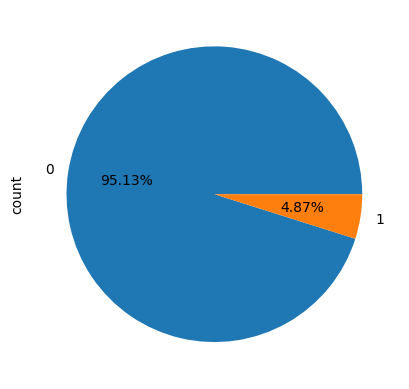

In [ ]:
import matplotlib.pyplot as plt

data = df['stroke'].value_counts()
data.plot(kind='pie',autopct='%.2f%%')
plt.show()

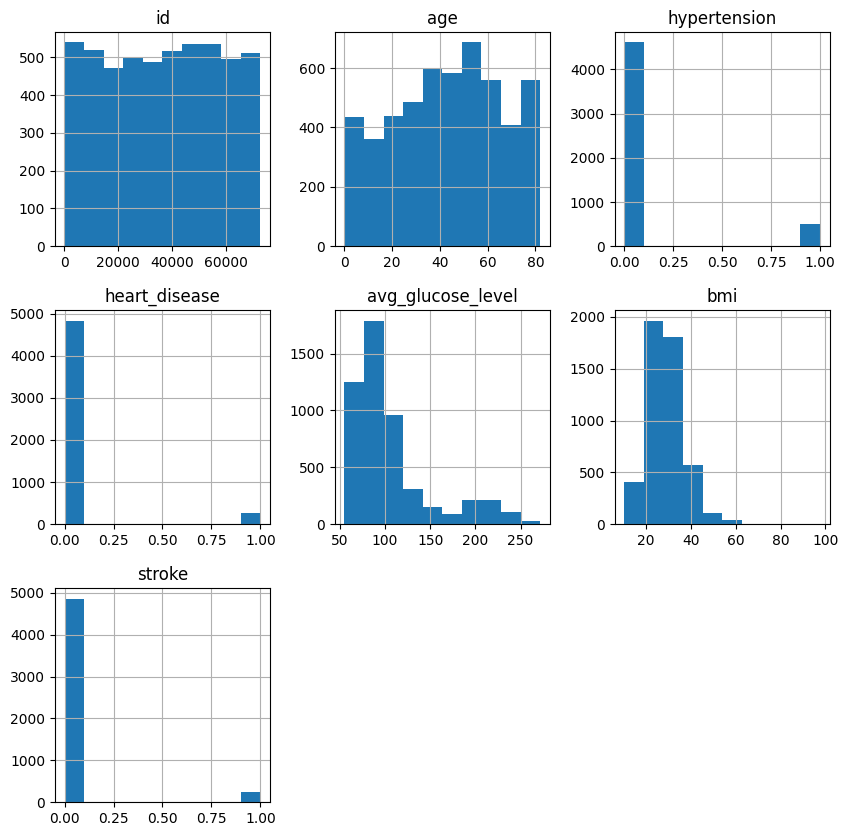

In [ ]:
# check histogram for continuous columns
df.hist(figsize=(10,10))
plt.show()

In [ ]:
df.isnull().sum()
# kolom bmi ada yang kosong

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [ ]:
df_X = df.drop(['id', 'stroke'],axis=1)
# definisikan kolom yg jadi input
df_y = df[['stroke']]
# definisikan kolom yg jadi output
cats = df_X.select_dtypes(include=['object', 'bool']).columns
print(cats)

Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='object')


In [ ]:
# import library yg dibutuhkan
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# data preprocessing dimulai
# membuat X and y. X untuk input variable, y untuk target class
df_X = df.drop(['id', 'stroke'],axis=1)
df_y = df[['stroke']]

#label encoding for y.
#merubah nilai yg ada di y menjadi 0 atau 1.
#sebenarnya ini tidak diperlukan karena nilai y di dataset sudah 0 atau 1
le = LabelEncoder()
df_y= le.fit_transform(df_y['stroke'])

#imputation. kita isi nilai kosong yg di kolom bmi dengan nilai median nya (atau bisa pakai cara lain)
df_X['bmi'] = df_X['bmi'].fillna(df_X['bmi'].median())

#categorical encoding
#merubah categorical value menjadi numerical value
#bisa pakai label encoding, ordinal atau one hot encoding
cats = df_X.select_dtypes(include=['object', 'bool']).columns
cat_features = list(cats.values)
le = LabelEncoder()
for i in cat_features:
  df_X[i] = le.fit_transform(df_X[i])

#menyimpan X dan y menjadi numpy arrays
X = df_X.astype(float).values
y = df_y.astype(float)

#hold-out method, dibagi menjadi training dan testing set. 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#scaling
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
# data preprocessing selesai

In [ ]:
X

array([[  1.  ,  67.  ,   0.  , ..., 228.69,  36.6 ,   1.  ],
       [  0.  ,  61.  ,   0.  , ..., 202.21,  28.1 ,   2.  ],
       [  1.  ,  80.  ,   0.  , ..., 105.92,  32.5 ,   2.  ],
       ...,
       [  0.  ,  35.  ,   0.  , ...,  82.99,  30.6 ,   2.  ],
       [  1.  ,  51.  ,   0.  , ..., 166.29,  25.6 ,   1.  ],
       [  0.  ,  44.  ,   0.  , ...,  85.28,  26.2 ,   0.  ]])

In [ ]:
y

array([1., 1., 1., ..., 0., 0., 0.])

In [ ]:
X_train

array([[ 1.18418048, -1.7467638 , -0.31719928, ..., -0.340693  ,
        -1.64591683, -1.29622579],
       [ 1.18418048, -0.63635252, -0.31719928, ...,  2.26654137,
        -0.78843307,  1.52066342],
       [ 1.18418048,  0.02989425,  3.15259225, ..., -0.32155489,
        -0.30772248,  0.58170035],
       ...,
       [-0.84446587, -1.87290652, -0.31719928, ..., -0.18803315,
        -1.43804198, -1.29622579],
       [ 1.18418048,  1.62888649, -0.31719928, ...,  2.01062472,
         0.27692553, -0.35726272],
       [-0.84446587,  0.11872715, -0.31719928, ..., -0.12416526,
         2.78441591,  1.52066342]])

In [ ]:
X_test

array([[ 1.18418048, -0.54751962, -0.31719928, ..., -0.90971812,
        -0.76244872, -1.29622579],
       [ 1.18418048, -0.14777156, -0.31719928, ..., -0.89992653,
        -0.07386327,  0.58170035],
       [-0.84446587, -1.569098  , -0.31719928, ..., -0.69675096,
        -0.82740961, -1.29622579],
       ...,
       [ 1.18418048, -0.05893866, -0.31719928, ..., -0.26569829,
        -0.21677723,  0.58170035],
       [-0.84446587,  0.60730811, -0.31719928, ..., -0.80846414,
        -0.63252693, -1.29622579],
       [-0.84446587,  0.74055746, -0.31719928, ..., -0.72746095,
        -0.46362862,  0.58170035]])

Accuracy  0.9419439008480104
Precision  0.4709719504240052
Recall  0.5
Confusion matrix  [[1444    0]
 [  89    0]]
F1  0.485052065838092


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


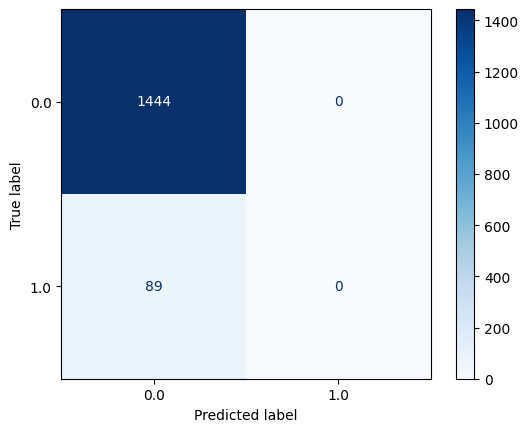

In [ ]:
#mulai melakukan modelling. model ML learning/ belajar dari training set
import numpy as np

model=LogisticRegression()
model.fit(X_train, y_train)

# membuat prediksi
y_pred = model.predict(X_test)

# y_pred jika di print out keluar vector prediksi nya
#menghitung performa model, dengan accuracy dll
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred, average='macro'))
print('Recall ',recall_score(y_test, y_pred, average='macro'))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))

# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

# plt.show()
disp.plot(cmap=plt.cm.Blues)

from sklearn.metrics import f1_score
print('F1 ',f1_score(y_test, y_pred, average='macro'))

In [ ]:
model.coef_

array([[-0.01878829,  1.55249921,  0.10370412,  0.07921647, -0.18371621,
        -0.06959651,  0.06033662,  0.19742689, -0.03156246,  0.02218138]])

In [ ]:
model.intercept_

array([-4.04531553])

Accuracy  0.9419439008480104
Precision  0.4709719504240052
Recall  0.5
Confusion matrix  [[1444    0]
 [  89    0]]


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


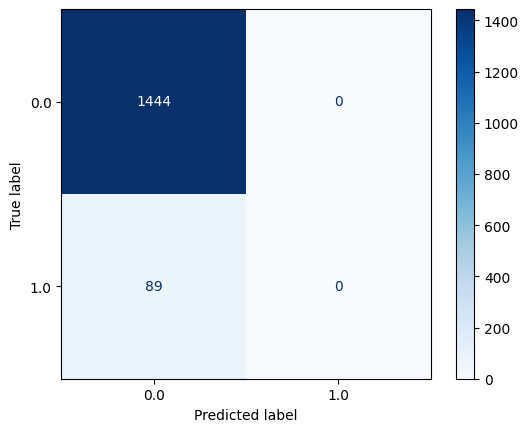

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model=KNeighborsClassifier(n_neighbors=10)
model.fit(X_train, y_train)

# membuat prediksi
y_pred = model.predict(X_test)

#menghitung performa model, dengan accuracy dll
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred, average='macro'))
print('Recall ',recall_score(y_test, y_pred, average='macro'))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))

# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

# plt.show()
disp.plot(cmap=plt.cm.Blues)

Accuracy  0.9060665362035225
Precision  0.5342465753424658
Recall  0.5284011329328644
Confusion matrix  [[1380   64]
 [  80    9]]


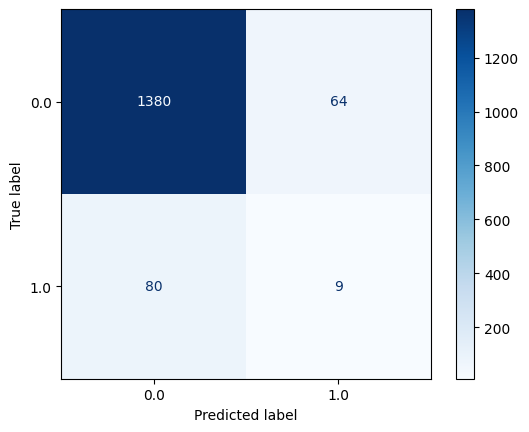

In [ ]:
from sklearn.tree import DecisionTreeClassifier

model=DecisionTreeClassifier(criterion="entropy")
model.fit(X_train, y_train)

# membuat prediksi
y_pred = model.predict(X_test)

#menghitung performa model, dengan accuracy dll
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred, average='macro'))
print('Recall ',recall_score(y_test, y_pred, average='macro'))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))

# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

# plt.show()
disp.plot(cmap=plt.cm.Blues)

Accuracy  0.9406392694063926
Precision  0.47093403004572176
Recall  0.49930747922437674
Confusion matrix  [[1442    2]
 [  89    0]]


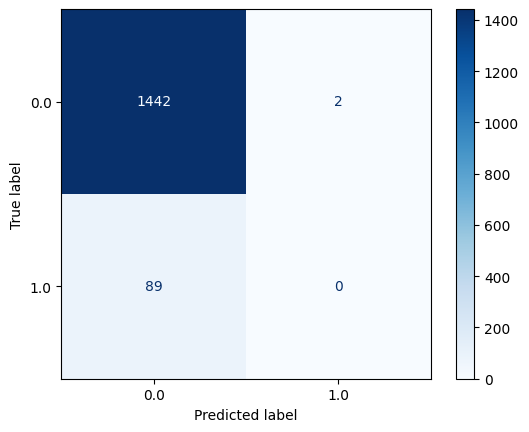

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model=RandomForestClassifier()
model.fit(X_train, y_train)

# membuat prediksi
y_pred = model.predict(X_test)

#menghitung performa model, dengan accuracy dll
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred, average='macro'))
print('Recall ',recall_score(y_test, y_pred, average='macro'))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))

# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

# plt.show()
disp.plot(cmap=plt.cm.Blues)

Accuracy  0.9419439008480104
Precision  0.4709719504240052
Recall  0.5
Confusion matrix  [[1444    0]
 [  89    0]]


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


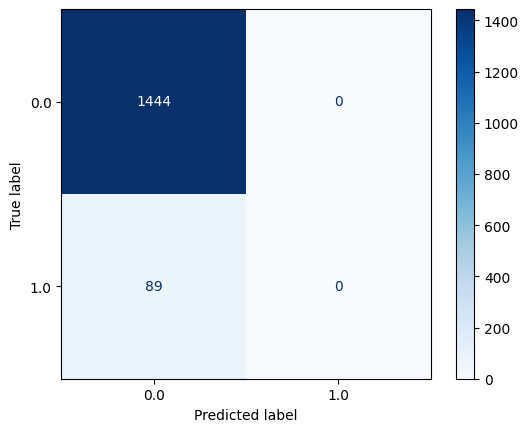

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

model=AdaBoostClassifier()
model.fit(X_train, y_train)

# membuat prediksi
y_pred = model.predict(X_test)

#menghitung performa model, dengan accuracy dll
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred, average='macro'))
print('Recall ',recall_score(y_test, y_pred, average='macro'))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))

# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
# plt.show()
disp.plot(cmap=plt.cm.Blues)

In [ ]:
# 1. Mendefinisikan kolom yang menjadi input (fitur)
# df_X berisi semua kolom kecuali 'id' (tidak relevan) dan 'stroke' (target).
df_X = df.drop(['id', 'stroke'], axis=1)

# 2. Mendefinisikan kolom yang menjadi output (target)
# df_y hanya berisi kolom 'stroke'.
df_y = df[['stroke']]

# 3. Mengidentifikasi atribut kategorikal pada data input
# memilih semua kolom dari df_X yang bertipe 'object' atau 'bool'.
cats = df_X.select_dtypes(include=['object', 'bool']).columns

print("--- Atribut Input (Fitur) ---")
print(df_X.columns)
print("\n--- Atribut Output (Target) ---")
print(df_y.columns)
print("\n--- Atribut Kategorikal pada Input ---")
print(cats)

--- Atribut Input (Fitur) ---
Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status'],
      dtype='object')

--- Atribut Output (Target) ---
Index(['stroke'], dtype='object')

--- Atribut Kategorikal pada Input ---
Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='object')


In [ ]:
#baca dataset menggunakan dataframe
import pandas as pd
from google.colab import drive

drive.mount('/content/drive/')
df_loan = pd.read_csv('/content/drive/MyDrive/Semester 5/Praktikum Penambangan Data/Pertemuan 3/loan_data.csv')
df_loan

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
1,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
2,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
3,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
4,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,LP002953,Male,Yes,3+,Graduate,No,5703,0.0,128.0,360.0,1.0,Urban,Y
377,LP002974,Male,Yes,0,Graduate,No,3232,1950.0,108.0,360.0,1.0,Rural,Y
378,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
379,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y


In [ ]:
# 'df_loan' adalah DataFrame yang sudah memuat dataset loan-status-prediction.
# Kolom 'Loan_ID' yang tidak relevan dapat dihapus terlebih dahulu.
df_loan = df_loan.drop('Loan_ID', axis=1)

# 1. Mendefinisikan kolom yang menjadi input (fitur)
# df_X_loan berisi semua kolom dari DataFrame kecuali kolom target 'Loan_Status'.
df_X_loan = df_loan.drop(['Loan_Status'], axis=1)

# 2. Mendefinisikan kolom yang menjadi output (target)
# df_y_loan hanya berisi kolom 'Loan_Status'.
df_y_loan = df_loan[['Loan_Status']]

# 3. Mengidentifikasi atribut kategorikal pada data input
# Kode ini memilih semua kolom dari df_X_loan yang bertipe 'object'.
cats_loan = df_X_loan.select_dtypes(include=['object']).columns

# Menampilkan hasil untuk verifikasi
print("--- Atribut Input (Fitur) ---")
print(df_X_loan.columns)
print("\n--- Atribut Output (Target) ---")
print(df_y_loan.columns)
print("\n--- Atribut Kategorikal pada Input ---")
print(cats_loan)

--- Atribut Input (Fitur) ---
Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='object')

--- Atribut Output (Target) ---
Index(['Loan_Status'], dtype='object')

--- Atribut Kategorikal pada Input ---
Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Property_Area'],
      dtype='object')


In [ ]:
# Import library yang dibutuhkan untuk preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- Langkah Preprocessing 1: Penanganan Nilai yang Hilang (Imputation) ---
# Mengisi nilai kosong pada kolom numerik dengan median
for col in ['LoanAmount', 'Loan_Amount_Term', 'Credit_History']:
    # Menggunakan cara penulisan yang disarankan untuk menghindari warning
    df_loan[col] = df_loan[col].fillna(df_loan[col].median())

# Mengisi nilai kosong pada kolom kategorikal dengan modus
for col in ['Gender', 'Married', 'Dependents', 'Self_Employed']:
    # Menggunakan cara penulisan yang disarankan untuk menghindari warning
    df_loan[col] = df_loan[col].fillna(df_loan[col].mode()[0])

# --- Langkah Preprocessing 2: Encoding Variabel Kategorikal ---
# Mengubah semua kolom bertipe 'object' menjadi angka
le = LabelEncoder()
for col in df_loan.select_dtypes(include=['object']).columns:
    df_loan[col] = le.fit_transform(df_loan[col])

# --- Setelah preprocessing, kita definisikan ulang X dan y dari df_loan yang sudah bersih ---
X = df_loan.drop('Loan_Status', axis=1)
y = df_loan['Loan_Status']

# --- Langkah Preprocessing 3: Membagi Data menjadi Data Latih dan Uji ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# --- Langkah Preprocessing 4: Penskalaan Fitur ---
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# --- Data sekarang SIAP untuk dilatihkan ke model ---
print("Data preprocessing selesai.")
print("Bentuk X_train:", X_train.shape)
print("Bentuk X_test:", X_test.shape)

Data preprocessing selesai.
Bentuk X_train: (266, 11)
Bentuk X_test: (115, 11)


Hasil Performa Model Logistic Regression:
Accuracy: 0.8087
Precision: 0.7900
Recall: 0.9875

Confusion Matrix untuk Logistic Regression:


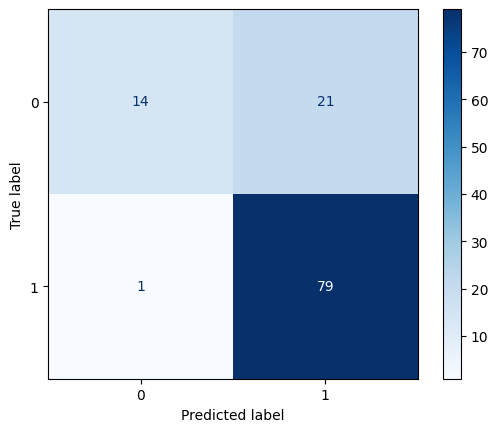

In [ ]:
# import library yang dibutuhkan
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# mulai melakukan modelling
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train, y_train)

# membuat prediksi
y_pred_lr = model_lr.predict(X_test)

# menghitung performa model
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)

# menampilkan hasil performa
print("Hasil Performa Model Logistic Regression:")
print(f"Accuracy: {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall: {recall_lr:.4f}")

# plot confusion matrix
print("\nConfusion Matrix untuk Logistic Regression:")
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr)
disp_lr.plot(cmap=plt.cm.Blues)
plt.show()

Hasil Performa Model K-Nearest Neighbors:
Accuracy: 0.8087
Precision: 0.7900
Recall: 0.9875

Confusion Matrix untuk K-Nearest Neighbors:


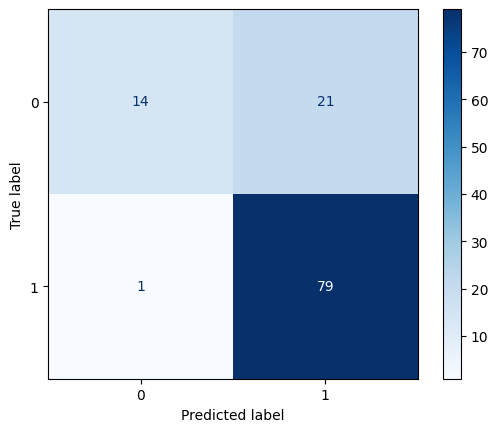

In [ ]:
# import library yang dibutuhkan
from sklearn.neighbors import KNeighborsClassifier

# mulai melakukan modelling
model_knn = KNeighborsClassifier()
model_knn.fit(X_train, y_train)

# membuat prediksi
y_pred_knn = model_knn.predict(X_test)

# menghitung performa model
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)

# menampilkan hasil performa
print("Hasil Performa Model K-Nearest Neighbors:")
print(f"Accuracy: {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall: {recall_knn:.4f}")

# plot confusion matrix
print("\nConfusion Matrix untuk K-Nearest Neighbors:")
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn)
disp_knn.plot(cmap=plt.cm.Blues)
plt.show()

Hasil Performa Model Decision Tree:
Accuracy: 0.7739
Precision: 0.8068
Recall: 0.8875

Confusion Matrix untuk Decision Tree:


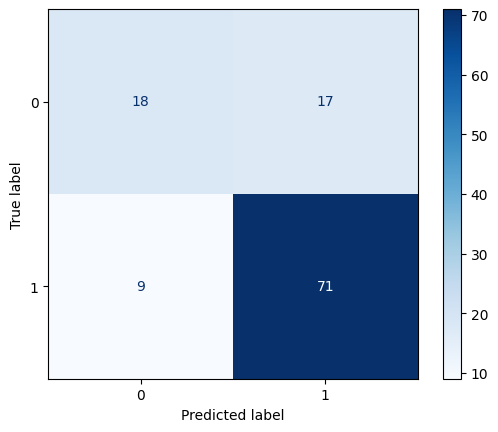

In [ ]:
# import library yang dibutuhkan
from sklearn.tree import DecisionTreeClassifier

# mulai melakukan modelling
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train, y_train)

# membuat prediksi
y_pred_dt = model_dt.predict(X_test)

# menghitung performa model
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)

# menampilkan hasil performa
print("Hasil Performa Model Decision Tree:")
print(f"Accuracy: {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall: {recall_dt:.4f}")

# plot confusion matrix
print("\nConfusion Matrix untuk Decision Tree:")
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt)
disp_dt.plot(cmap=plt.cm.Blues)
plt.show()

Hasil Performa Model Random Forest:
Accuracy: 0.8261
Precision: 0.8061
Recall: 0.9875

Confusion Matrix untuk Random Forest:


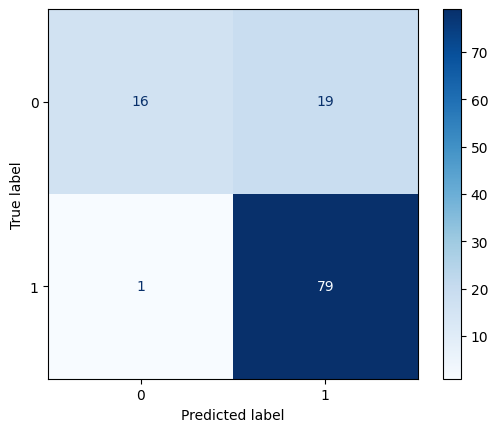

In [ ]:
# import library yang dibutuhkan
from sklearn.ensemble import RandomForestClassifier

# mulai melakukan modelling
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)

# membuat prediksi
y_pred_rf = model_rf.predict(X_test)

# menghitung performa model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)

# menampilkan hasil performa
print("Hasil Performa Model Random Forest:")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")

# plot confusion matrix
print("\nConfusion Matrix untuk Random Forest:")
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp_rf.plot(cmap=plt.cm.Blues)
plt.show()